# SokoBot: empirical evaluation

This notebook is the results chapter in executable form. Every number in the text of the
thesis should be traceable to a cell here.

**Experimental setup.** One machine (AMD Ryzen, 16 hardware threads, CachyOS). Each solver
configuration attempts every map in the benchmark once, with a wall-clock limit of
$T = 10$ s per map. A map counts as solved only if the returned move string is replayed
from the start position and ends with every box on a goal (`valid = 1`).

| file | line-up (thread ids) | maps |
|---|---|---|
| `data/old.csv` | 0, 1, 2, 3 (forward threads only) | full benchmark |
| `data/new.csv` | 0, 1, 3, 4 (thread 2 replaced by the backward thread) | full benchmark |
| `data/five.csv` | 0, 1, 2, 3, 4 | the 120 maps `new` did not solve |

**Notation.** $M$ is the set of maps, $S_c \subseteq M$ the maps solved by configuration $c$,
$t_c(m)$ the wall-clock time of $c$ on map $m$ (only meaningful for $m \in S_c$).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from sokostats import classify, compare_runs, load_run, threads_that_ran

DATA = Path("data")
TIMEOUT_MS = 10_000
RNG = np.random.default_rng(20261106)  # fixed seed: bootstrap intervals are reproducible

PALETTE = {"old": "#8a8984", "new": "#2a78d6", "five": "#eb6834"}
INK, MUTED, GRID = "#1f1f1e", "#5f5e58", "#e4e3de"
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
})
pd.set_option("display.max_columns", 40, "display.width", 160, "display.precision", 3)

runs = {name: load_run(DATA / f"{name}.csv") for name in ("old", "new", "five")}
for name, run in runs.items():
    run["result"] = classify(run)
    run["solved_valid"] = run["solved"] & (run["valid"] == 1)
    print(f"{name:5s} maps={len(run):5d}  line-up={run['lineup'].iloc[0]:10s}  "
          f"solved={run['solved'].sum():5d}  invalid={int((run['solved'] & (run['valid'] != 1)).sum())}")

old   maps= 2746  line-up=0,1,2,3     solved= 2491  invalid=0
new   maps= 2746  line-up=0,1,3,4     solved= 2626  invalid=0
five  maps=  120  line-up=0,1,2,3,4   solved=   10  invalid=0


## 1. Coverage

The primary metric is coverage $|S_c| / |M|$. Because $|M|$ is finite and each map is a
Bernoulli outcome, we report a 95 % Wilson score interval

$$
\hat p \pm \frac{z}{1+z^2/n}\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}},
\qquad \text{centre } \frac{\hat p + z^2/2n}{1 + z^2/n}, \quad z = 1.96 .
$$

The interval describes uncertainty about the solver's rate on maps *like these*; the
benchmark is a fixed set, so it is not a claim about Sokoban in general.

In [2]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z / (1 + z * z / n) * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return centre - half, centre + half

old, new, five = runs["old"], runs["new"], runs["five"]
n = len(new)
five_total = new["solved_valid"].sum() + five["solved_valid"].sum()  # five ran on new's failures

rows = []
for label, k in [("old  (0,1,2,3)", old["solved_valid"].sum()),
                 ("new  (0,1,3,4)", new["solved_valid"].sum()),
                 ("five (0,1,2,3,4)*", five_total)]:
    lo, hi = wilson(k, n)
    rows.append({"configuration": label, "solved": k, "maps": n, "coverage": k / n,
                 "95% CI low": lo, "95% CI high": hi})
coverage = pd.DataFrame(rows).set_index("configuration")
coverage

,solved,maps,coverage,95% CI low,95% CI high
configuration,,,,,
"old (0,1,2,3)",2491,2746,0.907,0.896,0.917
"new (0,1,3,4)",2626,2746,0.956,0.948,0.963
"five (0,1,2,3,4)*",2636,2746,0.960,0.952,0.967


\* *five* was only run on the 120 maps that *new* did not solve, so its total is
$|S_\text{new}| + |S_\text{five} \cap (M \setminus S_\text{new})|$. This assumes *five*
would also solve everything *new* solves, which holds if adding a thread never removes a
solution; it can only make solves slower (CPU contention), not fail, unless a map was near
the time limit. Section 4 checks how many *new* solves were close to the limit.

## 2. Paired comparison: old versus new

Both line-ups ran on the same maps, so the comparison is paired.

**Coverage: exact McNemar test.** Let $b = |S_\text{new} \setminus S_\text{old}|$ (gained)
and $c = |S_\text{old} \setminus S_\text{new}|$ (lost). Under $H_0$ (no difference) each
discordant map is equally likely to fall either way, so $b \sim \text{Binomial}(b+c, 1/2)$.

**Speed: Wilcoxon signed-rank test** on $\log t_\text{old}(m) - \log t_\text{new}(m)$ over
$m \in S_\text{old} \cap S_\text{new}$, with the geometric-mean speed-up
$\exp\big(\overline{\log t_\text{old} - \log t_\text{new}}\big)$ and a 10 000-sample
bootstrap 95 % interval. Logs are used because solve times span five orders of magnitude.
Times below 1 ms are floored at 1 ms so timer noise on trivial maps does not dominate.

In [3]:
m = compare_runs(new, old)
gained = int((m["change"] == "gained").sum())
lost = int((m["change"] == "lost").sum())
mcnemar = stats.binomtest(gained, gained + lost, 0.5)
print(f"gained b = {gained}, lost c = {lost}")
print(f"exact McNemar p = {mcnemar.pvalue:.3g}")

both = m.dropna(subset=["ratio"]).copy()
lt_old = np.log(np.maximum(both["time_ms_old"], 1.0))
lt_new = np.log(np.maximum(both["time_ms_new"], 1.0))
d = (lt_old - lt_new).to_numpy()
w = stats.wilcoxon(d)
boot = np.exp(RNG.choice(d, size=(10_000, len(d))).mean(axis=1))
print(f"\nmaps solved by both: {len(both)}")
print(f"geometric-mean speed-up new over old: {np.exp(d.mean()):.2f}x "
      f"(95% bootstrap CI {np.percentile(boot, 2.5):.2f}-{np.percentile(boot, 97.5):.2f})")
print(f"Wilcoxon signed-rank p = {w.pvalue:.3g}")
print(f"total time on shared maps: old {both['time_ms_old'].sum()/1e3:.1f} s, "
      f"new {both['time_ms_new'].sum()/1e3:.1f} s")
print(f"new faster on {(d > 0).mean():.1%} of shared maps, slower on {(d < 0).mean():.1%}")

gained b = 145, lost c = 10
exact McNemar p = 7.7e-32



maps solved by both: 2481
geometric-mean speed-up new over old: 1.31x (95% bootstrap CI 1.26-1.37)
Wilcoxon signed-rank p = 1.43e-48
total time on shared maps: old 423.5 s, new 181.2 s
new faster on 37.3% of shared maps, slower on 19.5%


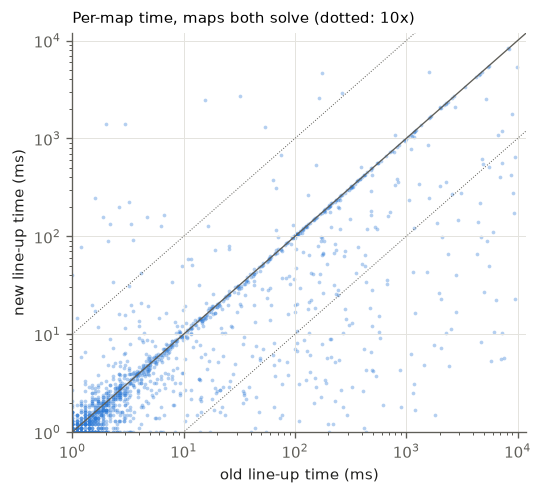

In [4]:
fig, ax = plt.subplots(figsize=(4.6, 4.2))
x = np.maximum(both["time_ms_old"], 1.0); y = np.maximum(both["time_ms_new"], 1.0)
ax.scatter(x, y, s=5, alpha=0.35, color=PALETTE["new"], linewidths=0)
lim = [1, TIMEOUT_MS * 1.2]
ax.plot(lim, lim, color=MUTED, lw=0.8)
ax.plot(lim, [v / 10 for v in lim], color=MUTED, lw=0.6, ls=":")
ax.plot(lim, [v * 10 for v in lim], color=MUTED, lw=0.6, ls=":")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("old line-up time (ms)"); ax.set_ylabel("new line-up time (ms)")
ax.set_title("Per-map time, maps both solve (dotted: 10x)", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 3. Cactus plot

The standard presentation for solver benchmarks: for each time budget $\tau$, the number of
maps solved within $\tau$, i.e. $|\{m \in S_c : t_c(m) \le \tau\}|$. A curve that is higher
everywhere dominates; where curves cross, one configuration is better at short budgets and
the other at long ones.

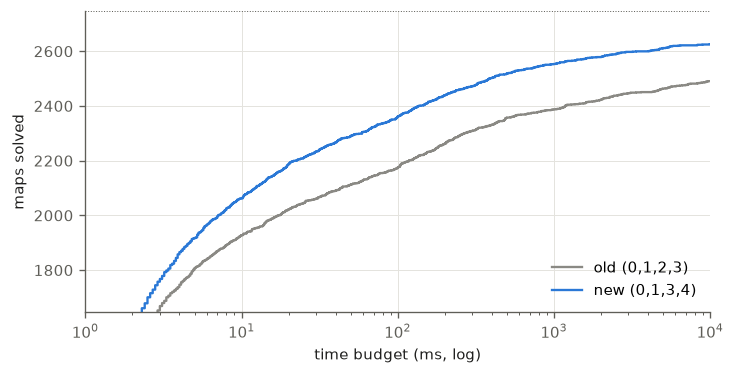

,old,new
<= 10 ms,1928,2063
<= 100 ms,2175,2361
<= 1000 ms,2388,2554
<= 5000 ms,2464,2612
<= 10000 ms,2491,2626


In [5]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
for name in ("old", "new"):
    t = np.sort(np.maximum(runs[name].loc[runs[name]["solved_valid"], "time_ms"], 1.0))
    ax.step(t, np.arange(1, len(t) + 1), where="post", color=PALETTE[name], lw=1.4,
            label=f"{name} ({runs[name]['lineup'].iloc[0]})")
ax.set_xscale("log"); ax.set_xlim(1, TIMEOUT_MS)
ax.set_ylim(int(0.6 * n), n)
ax.axhline(n, color=MUTED, lw=0.6, ls=":")
ax.set_xlabel("time budget (ms, log)"); ax.set_ylabel("maps solved")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

budgets = [10, 100, 1_000, 5_000, 10_000]
pd.DataFrame({name: [(runs[name]["solved_valid"] & (runs[name]["time_ms"] <= b)).sum() for b in budgets]
              for name in ("old", "new")}, index=[f"<= {b} ms" for b in budgets])

## 4. Where the time goes

Solve times are heavy-tailed: a few maps take most of the wall-clock time. The curve below
sorts *new*'s solved maps from slowest to fastest and plots the cumulative share of total
solve time. We also count solves within 20 % of the limit, which are the ones most at risk
of flipping to a time-out on a slower or busier machine.

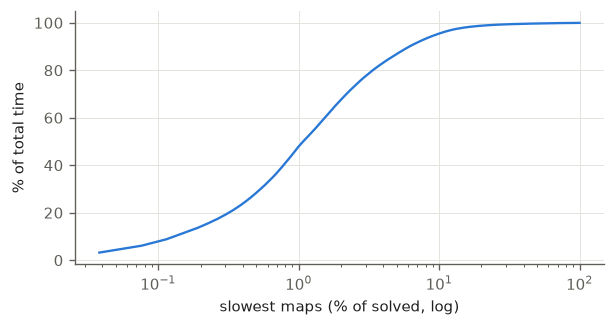

slowest 1% (26 maps) take 47.7% of the 308 s total
slowest 5% (131 maps) take 86.9% of the 308 s total
slowest 10% (262 maps) take 95.5% of the 308 s total
solves within 20% of the limit: 4
median solve time 1.2 ms, 90th percentile 101 ms


In [6]:
t = new.loc[new["solved_valid"], "time_ms"].sort_values(ascending=False).to_numpy()
share = np.cumsum(t) / t.sum()
fig, ax = plt.subplots(figsize=(5.2, 2.8))
ax.plot(np.arange(1, len(t) + 1) / len(t) * 100, share * 100, color=PALETTE["new"], lw=1.4)
ax.set_xscale("log"); ax.set_xlabel("slowest maps (% of solved, log)"); ax.set_ylabel("% of total time")
plt.tight_layout(); plt.show()

for frac in (0.01, 0.05, 0.10):
    k = max(1, int(frac * len(t)))
    print(f"slowest {frac:.0%} ({k} maps) take {t[:k].sum() / t.sum():.1%} of the {t.sum()/1e3:.0f} s total")
near = (new["solved_valid"] & (new["time_ms"] > 0.8 * TIMEOUT_MS)).sum()
print(f"solves within 20% of the limit: {near}")
print(f"median solve time {np.median(t):.1f} ms, 90th percentile {np.percentile(t, 90):.0f} ms")

## 5. Thread roles

Each line-up is a portfolio: threads run in parallel and the first valid solution wins.
A thread earns its slot if it wins maps that no other thread would. We report

* **wins**: maps where the thread returned the accepted solution;
* **hard wins**: wins taking at least 100 ms (on trivial maps the winner is a coin flip);
* **swap ablation**: the old and new line-ups differ only by T2 → T4, so the paired result of
  Section 2 is exactly the marginal value of that swap.

In [7]:
def wins(run):
    s = run[run["solved_valid"]]
    return pd.DataFrame({
        "wins": s["thread"].value_counts(),
        "hard wins (>=100 ms)": s.loc[s["time_ms"] >= 100, "thread"].value_counts(),
    }).fillna(0).astype(int).rename(index=lambda t: f"T{t}").sort_index()

pd.concat({"old": wins(old), "new": wins(new)}, axis=1).fillna(0).astype(int)

old                       new                     
       wins hard wins (>=100 ms) wins hard wins (>=100 ms)
thread                                                    
T0      915                   91  653                   41
T1      750                  125  600                   73
T2      280                   43    0                    0
T3      546                   58  441                   22
T4        0                    0  932                  129

In [8]:
gained_rows = m[m["change"] == "gained"].merge(new[["map", "thread"]], on="map")
lost_rows = m[m["change"] == "lost"].merge(old[["map", "thread"]], on="map")
print("maps gained by the swap, by winning thread in new:",
      gained_rows["thread"].value_counts().rename(index=lambda t: f"T{t}").to_dict())
print("maps lost by the swap, by winning thread in old: ",
      lost_rows["thread"].value_counts().rename(index=lambda t: f"T{t}").to_dict())
five_gain = five[five["solved_valid"]]
print(f"\nfive-thread run on the {len(five)} maps new missed: solved {len(five_gain)}, "
      f"winners {five_gain['thread'].value_counts().rename(index=lambda t: f'T{t}').to_dict()}")
recovered = set(five_gain["map"]) & set(lost_rows["map"])
print(f"of these, previously lost by the swap: {len(recovered)} of {len(lost_rows)}")

maps gained by the swap, by winning thread in new: {'T4': 144, 'T1': 1}
maps lost by the swap, by winning thread in old:  {'T2': 10}

five-thread run on the 120 maps new missed: solved 10, winners {'T2': 10}
of these, previously lost by the swap: 10 of 10


## 6. Difficulty

How coverage falls with instance size. Box count $k$ bounds the branching factor
($\le 4k$ pushes per state) and floor size $|F|$ bounds the state space
($\binom{|F|}{k}\,|F|$ before symmetry), so both are natural difficulty proxies. Spearman's
$\rho$ tests whether solve time rises monotonically with each, on solved maps.

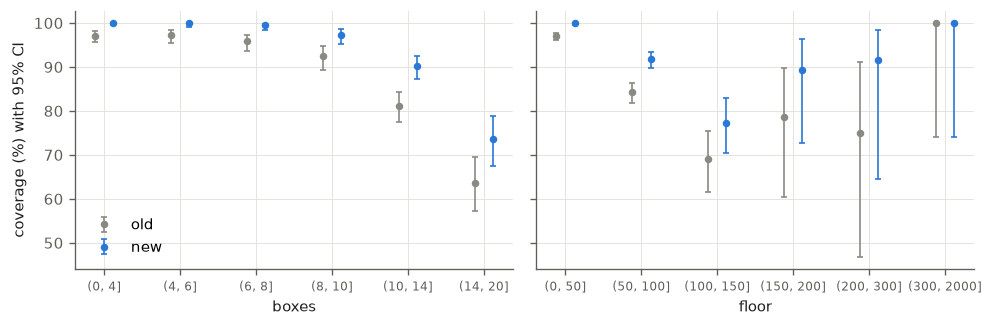

Spearman rho(time, boxes) = 0.770, p = 0
Spearman rho(time, floor) = 0.688, p = 0


,maps,solved,coverage,CI low,CI high
boxes,,,,,
"(0, 4]",707,707,1.000,0.995,1.000
"(4, 6]",487,487,1.000,0.992,1.000
"(6, 8]",460,458,0.996,0.984,0.999
"(8, 10]",376,366,0.973,0.952,0.985
"(10, 14]",488,440,0.902,0.872,0.925
"(14, 20]",228,168,0.737,0.676,0.790


In [9]:
def rate_by(run, column, bins):
    groups = pd.cut(run[column], bins)
    g = run.groupby(groups, observed=True)["solved_valid"].agg(maps="size", solved="sum")
    g["coverage"] = g["solved"] / g["maps"]
    ci = [wilson(s, k) for s, k in zip(g["solved"], g["maps"])]
    g["CI low"] = [c[0] for c in ci]; g["CI high"] = [c[1] for c in ci]
    return g

tables = {"boxes": [0, 4, 6, 8, 10, 14, 20, 60], "floor": [0, 50, 100, 150, 200, 300, 2000]}
fig, axes = plt.subplots(1, 2, figsize=(8.4, 2.8), sharey=True)
for ax, (column, bins) in zip(axes, tables.items()):
    for name in ("old", "new"):
        g = rate_by(runs[name], column, bins)
        xs = np.arange(len(g)) + (0.12 if name == "new" else -0.12)
        ax.errorbar(xs, g["coverage"] * 100,
                    yerr=[(g["coverage"] - g["CI low"]) * 100, (g["CI high"] - g["coverage"]) * 100],
                    fmt="o", ms=3.5, capsize=2, lw=1, color=PALETTE[name], label=name)
    ax.set_xticks(range(len(g)), [str(b) for b in g.index], fontsize=7)
    ax.set_xlabel(column)
axes[0].set_ylabel("coverage (%) with 95% CI"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

s = new[new["solved_valid"]]
for column in ("boxes", "floor"):
    rho, p = stats.spearmanr(s[column], s["time_ms"])
    print(f"Spearman rho(time, {column}) = {rho:.3f}, p = {p:.2g}")
rate_by(new, "boxes", tables["boxes"])

## 7. Failure taxonomy

For each unsolved map, the per-thread outcome says *why* it failed:

* **out of time**: some thread was still searching at the limit (more time or a better
  heuristic could help);
* **out of memory**: every thread filled its state pool;
* **search ran dry**: every thread emptied its queue or refused to start. If the map is
  solvable this proves a pruning rule removed every solution, i.e. the pruning is unsound on
  that map. These are bugs, not hardness.

In [10]:
unsolved = new[~new["solved_valid"]]
print(unsolved["result"].value_counts().to_string())
ran = threads_that_ran(new)
pd.DataFrame({f"T{t}": unsolved[f"t{t}_outcome"].value_counts() for t in ran}).fillna(0).astype(int)

result
out of time      119
out of memory      1


,T0,T1,T3,T4
exhausted,5,25,5,0
pool_full,0,0,0,11
stopped,115,95,115,109


In [11]:
# Threads that exhausted on maps another configuration proves solvable: direct evidence of
# incomplete pruning.
solvable = set(old.loc[old["solved_valid"], "map"]) | set(new.loc[new["solved_valid"], "map"]) \
         | set(five.loc[five["solved_valid"], "map"])
rows = []
for name, run in runs.items():
    for t in threads_that_ran(run):
        col = f"t{t}_outcome"
        dry = run[run[col].isin(["exhausted", "hopeless"]) & run["map"].isin(solvable)]
        rows.append({"run": name, "thread": f"T{t}", "ran dry on a solvable map": len(dry)})
pd.DataFrame(rows).pivot(index="thread", columns="run", values="ran dry on a solvable map").fillna(0).astype(int)

run,five,new,old
thread,,,
T0,0,38,59
T1,2,114,135
T2,0,0,59
T3,0,36,60
T4,0,0,0


## 8. Threats to validity

* **Single run per configuration.** Thread scheduling makes wall-clock races
  non-deterministic. Maps decided within a few milliseconds may flip between runs; the
  ≥ 100 ms *hard wins* column is the robust one. Repeating each configuration three times
  and reporting the median would remove this.
* **One machine.** Coverage at a fixed wall-clock limit depends on core count and clock
  speed. The 16-thread Ryzen runs four solver threads, so there is no CPU contention here.
* **Five-thread total is partly inferred** (see Section 1).
* **Benchmark composition.** The maps come from public collections of mixed difficulty, so
  coverage is dominated by easy collections. Per-collection tables would show where the
  gains concentrate.
* **Validity is checked by replay**, so reported solutions are correct. Optimality (fewest
  moves or pushes) is not measured or claimed.